<a href="https://colab.research.google.com/github/OHD01/Quantitative-Hedge-Fund-Strategy-Sigma-Apex-Capital/blob/main/Copy_of_DAIF_Oussama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning sous Python – Contrôle continu
**DAIF_Oussama** – MBA2 Trading et Finance de Marché

Stratégie de trading sur le CAC40 (^FCHI) avec un réseau de neurones feedforward (apprentissage supervisé).

## Imports

In [ ]:
# !pip install yfinance tensorflow scikit-learn matplotlib   # à décommenter sur Colab si besoin
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

np.random.seed(42)
tf.random.set_seed(42)

## Question 1 – Téléchargement des données Yahoo Finance (CAC40, 01/01/2017 → 01/01/2022)

In [ ]:
df = yf.download("^FCHI", start="2017-01-01", end="2022-01-01", auto_adjust=False, progress=False)

# Selon la version de yfinance, les colonnes peuvent être en MultiIndex : on les aplatit
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[["Open", "High", "Low", "Close"]].dropna()
print(df.shape)
df.head()

(1280, 4)


Price,Open,High,Low,Close
Date,,,,
2017-01-02,4845.959961,4896.009766,4843.930176,4882.379883
2017-01-03,4904.770020,4929.600098,4896.109863,4899.330078
2017-01-04,4912.950195,4913.939941,4879.229980,4899.399902
2017-01-05,4881.720215,4905.839844,4874.790039,4900.640137
2017-01-06,4885.189941,4911.490234,4874.419922,4909.839844


## Question 2 –
Les indicateurs techniques sont codés avec pandas (mêmes formules que TA-Lib : lissage de Wilder pour ADX et RSI), ce qui évite d'installer TA-Lib.

In [ ]:
def rsi(close, n=20):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    avg_loss = loss.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    rs = avg_gain / avg_loss
    return 100 - 100 / (1 + rs)

def adx(high, low, close, n=20):
    up = high.diff()
    down = -low.diff()
    plus_dm = np.where((up > down) & (up > 0), up, 0.0)
    minus_dm = np.where((down > up) & (down > 0), down, 0.0)
    prev_close = close.shift(1)
    tr = pd.concat([high - low, (high - prev_close).abs(), (low - prev_close).abs()], axis=1).max(axis=1)
    atr = tr.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    plus_di = 100 * pd.Series(plus_dm, index=close.index).ewm(alpha=1/n, adjust=False, min_periods=n).mean() / atr
    minus_di = 100 * pd.Series(minus_dm, index=close.index).ewm(alpha=1/n, adjust=False, min_periods=n).mean() / atr
    dx = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di)
    return dx.ewm(alpha=1/n, adjust=False, min_periods=n).mean()

def stochastic(high, low, close, fastk_period=14, slowk_period=3, slowd_period=3):
    lowest = low.rolling(fastk_period).min()
    highest = high.rolling(fastk_period).max()
    fastk = 100 * (close - lowest) / (highest - lowest)
    slowk = fastk.rolling(slowk_period).mean()
    slowd = slowk.rolling(slowd_period).mean()
    return slowk, slowd

def cci(high, low, close, n=20):
    tp = (high + low + close) / 3
    sma = tp.rolling(n).mean()
    mad = tp.rolling(n).apply(lambda x: np.mean(np.abs(x - x.mean())), raw=True)
    return (tp - sma) / (0.015 * mad)

data = df.copy()
data["ret_1d"] = data["Close"].pct_change(1) * 100     # variation % Close vs J-1
data["ret_8d"] = data["Close"].pct_change(8) * 100     # variation % Close vs J-8
data["ADX"] = adx(data["High"], data["Low"], data["Close"], 20)
data["RSI"] = rsi(data["Close"], 20)
data["SlowK"], data["SlowD"] = stochastic(data["High"], data["Low"], data["Close"], 14, 3)
data["CCI"] = cci(data["High"], data["Low"], data["Close"], 20)
data["Vol10"] = data["Close"].pct_change().rolling(10).std()   # volatilité 10 jours

features = ["ret_1d", "ret_8d", "ADX", "RSI", "SlowK", "SlowD", "CCI", "Vol10"]
data[features].tail()

Price,ret_1d,ret_8d,ADX,RSI,SlowK,SlowD,CCI,Vol10
Date,,,,,,,,
2021-12-27,0.759323,3.071184,14.213507,58.741688,95.063118,89.285757,124.646507,0.009282
2021-12-28,0.570273,2.513038,14.036126,60.212040,95.788232,93.988175,150.614548,0.008652
2021-12-29,-0.272797,3.391117,13.926790,59.144639,95.823113,95.558155,133.017711,0.008910
2021-12-30,0.163512,4.412307,13.822920,59.595328,94.462830,95.358059,127.375605,0.008480
2021-12-31,-0.281605,2.699782,13.624460,58.425012,91.396457,93.894133,103.808418,0.007321


## Question 3 – Label
`1` si hausse à J+1 **et** variation de Close vs J-8 positive, `0` sinon.

In [ ]:
data["next_ret"] = data["Close"].shift(-1) / data["Close"] - 1      # rendement de J à J+1
hausse_j1 = data["Close"].shift(-1) > data["Close"]
data["Label"] = ((hausse_j1) & (data["ret_8d"] > 0)).astype(int)

# On retire les lignes avec NaN (début : indicateurs ; fin : pas de J+1)
data = data.dropna(subset=features + ["next_ret"])
print(data.shape)
print(data["Label"].value_counts(normalize=True))

(1241, 14)
Label
0    0.678485
1    0.321515
Name: proportion, dtype: float64


## Question 4 – Séparation train / test (chronologique, sans mélange) et StandardScaler

In [ ]:
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]

X_train, y_train = train[features].values, train["Label"].values
X_test,  y_test  = test[features].values,  test["Label"].values

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit uniquement sur le train (pas de fuite d'information)
X_test_s  = scaler.transform(X_test)

print("Train :", X_train_s.shape, "| Test :", X_test_s.shape)
print("Période test :", test.index[0].date(), "→", test.index[-1].date())

Train : (992, 8) | Test : (249, 8)
Période test : 2021-01-14 → 2021-12-30


## Question 5 – Définition du réseau de neurones

In [ ]:
model = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(512, activation="elu"),  Dropout(0.15),
    Dense(256, activation="relu"), Dropout(0.15),
    Dense(128, activation="elu"),  Dropout(0.15),
    Dense(32,  activation="relu"), Dropout(0.15),
    Dense(1,   activation="sigmoid"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,993 (675.75 KB)

 Trainable params: 172,993 (675.75 KB)

 Non-trainable params: 0 (0.00 B)

## Question 6 – Compilation

In [ ]:
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

## Question 7 – Entraînement

Epoch 1/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6925 - loss: 0.5478
Epoch 2/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7127 - loss: 0.4796
Epoch 3/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7228 - loss: 0.4611
Epoch 4/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7409 - loss: 0.4365
Epoch 5/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7470 - loss: 0.4297
Epoch 6/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7369 - loss: 0.4225
Epoch 7/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7530 - loss: 0.4122
Epoch 8/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7288 - loss: 0.4158
Epoch 9/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7550 - loss: 0.4040
Epoch 10/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7409 - loss: 0.4112
Epoch 11/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7480 - loss: 0.4056
Epoch 12/25
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7450 - 

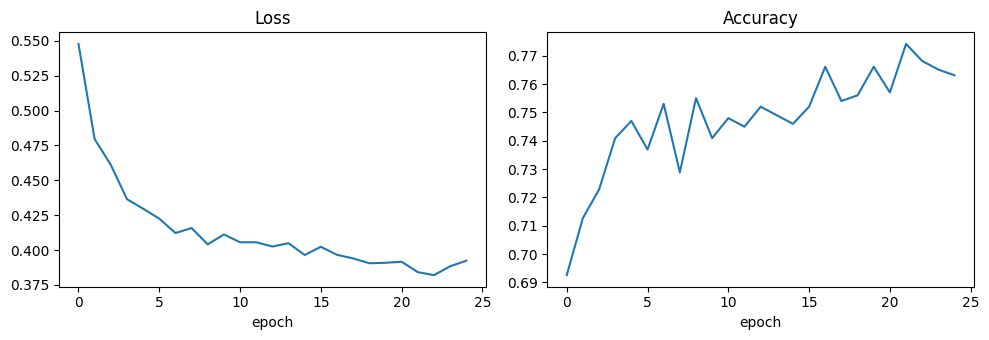

In [ ]:
history = model.fit(X_train_s, y_train, batch_size=64, epochs=25, verbose=1)

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1); plt.plot(history.history["loss"]); plt.title("Loss"); plt.xlabel("epoch")
plt.subplot(1, 2, 2); plt.plot(history.history["accuracy"]); plt.title("Accuracy"); plt.xlabel("epoch")
plt.tight_layout(); plt.show()

## Question 8 – Prédiction sur les données de test

In [ ]:
proba = model.predict(X_test_s).ravel()
y_pred = (proba > 0.5).astype(int)
print("Nombre de signaux d'achat prédits :", y_pred.sum(), "sur", len(y_pred), "jours")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Nombre de signaux d'achat prédits : 124 sur 249 jours


## Question 9 – Qualité de la prédiction

Matrice de confusion :
 [[103  49]
 [ 22  75]]


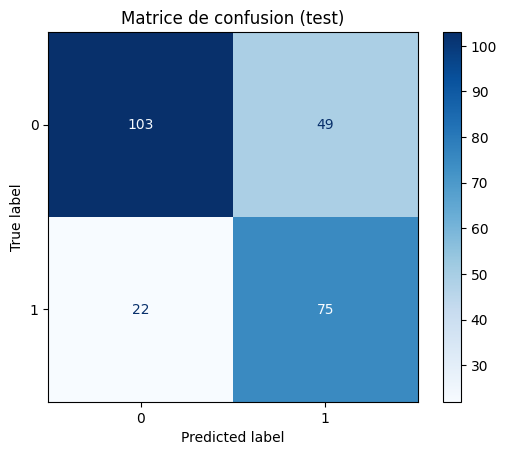

                   precision    recall  f1-score   support

0 (pas de hausse)       0.82      0.68      0.74       152
       1 (hausse)       0.60      0.77      0.68        97

         accuracy                           0.71       249
        macro avg       0.71      0.73      0.71       249
     weighted avg       0.74      0.71      0.72       249



In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Matrice de confusion :\n", cm)
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(cmap="Blues")
plt.title("Matrice de confusion (test)"); plt.show()

print(classification_report(y_test, y_pred, target_names=["0 (pas de hausse)", "1 (hausse)"], zero_division=0))

## Question 10 – Backtest
**Règles :** si le modèle prédit `1` à la clôture du jour J, on achète le CAC40 à la clôture de J et on revend à la clôture de J+1 (1 ordre = 1 aller-retour d'un jour). Si la prédiction est `0`, on reste hors marché. Pas de vente à découvert, frais de transaction ignorés (paramètre `frais` modifiable).

In [ ]:
capital_initial = 100_000
frais = 0.0            # frais par aller-retour (ex. 0.0005 = 5 bps)

bt = test[["Close", "next_ret"]].copy()
bt["signal"] = y_pred
bt["strat_ret"] = bt["signal"] * (bt["next_ret"] - frais)
bt["pnl"] = bt["strat_ret"] * capital_initial          # P&L en € par ordre (capital fixe)

# Courbes de capital (composition quotidienne)
bt["cum_strat"] = (1 + bt["strat_ret"]).cumprod()
bt["cum_bh"] = (1 + bt["next_ret"]).cumprod()          # Buy & Hold de référence

# ---- Bilan des ordres ----
ordres = bt[bt["signal"] == 1]
n_ordres = len(ordres)
gagnants = (ordres["strat_ret"] > 0).sum()
perdants = (ordres["strat_ret"] < 0).sum()

bilan = pd.Series({
    "Nombre total d'ordres": n_ordres,
    "Ordres gagnants": gagnants,
    "Ordres perdants": perdants,
    "Taux de réussite (%)": round(100 * gagnants / n_ordres, 2) if n_ordres else np.nan,
    "Gain moyen par ordre gagnant (%)": round(100 * ordres.loc[ordres["strat_ret"] > 0, "strat_ret"].mean(), 3),
    "Perte moyenne par ordre perdant (%)": round(100 * ordres.loc[ordres["strat_ret"] < 0, "strat_ret"].mean(), 3),
    "P&L total (€, capital fixe 100 000 €)": round(ordres["pnl"].sum(), 2),
})
print("===== BILAN =====")
print(bilan.to_string())

# ---- Statistiques de la stratégie ----
jours = 252
rend_cum = bt["cum_strat"].iloc[-1] - 1
rend_annuel = bt["cum_strat"].iloc[-1] ** (jours / len(bt)) - 1
vol_annuelle = bt["strat_ret"].std() * np.sqrt(jours)
sharpe = (bt["strat_ret"].mean() * jours) / vol_annuelle if vol_annuelle > 0 else np.nan
max_dd = (bt["cum_strat"] / bt["cum_strat"].cummax() - 1).min()

stats = pd.DataFrame({
    "Stratégie ML": [rend_cum, rend_annuel, vol_annuelle, sharpe, max_dd],
    "Buy & Hold": [
        bt["cum_bh"].iloc[-1] - 1,
        bt["cum_bh"].iloc[-1] ** (jours / len(bt)) - 1,
        bt["next_ret"].std() * np.sqrt(jours),
        (bt["next_ret"].mean() * jours) / (bt["next_ret"].std() * np.sqrt(jours)),
        (bt["cum_bh"] / bt["cum_bh"].cummax() - 1).min(),
    ],
}, index=["Rendement cumulé", "Rendement annualisé", "Volatilité annualisée", "Ratio de Sharpe (rf=0)", "Max drawdown"])
print("\n===== STATISTIQUES =====")
print(stats.round(4))

===== BILAN =====
Nombre total d'ordres                      124.000
Ordres gagnants                             75.000
Ordres perdants                             49.000
Taux de réussite (%)                        60.480
Gain moyen par ordre gagnant (%)             0.462
Perte moyenne par ordre perdant (%)         -0.411
P&L total (€, capital fixe 100 000 €)    14495.950

===== STATISTIQUES =====
                        Stratégie ML  Buy & Hold
Rendement cumulé              0.1537      0.2591
Rendement annualisé           0.1556      0.2626
Volatilité annualisée         0.0635      0.1406
Ratio de Sharpe (rf=0)        2.3113      1.7289
Max drawdown                 -0.0314     -0.0638


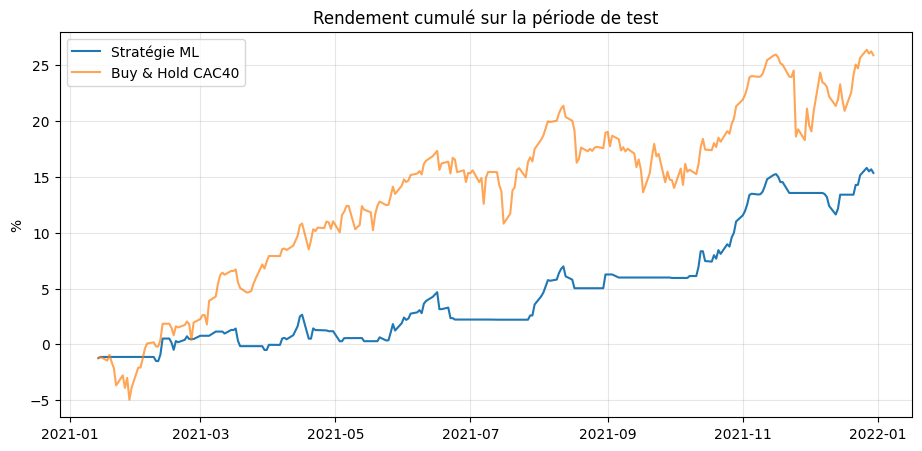

Rendement cumulé de la stratégie : 15.37%


In [ ]:
# ---- Rendement cumulé sur la période de test ----
plt.figure(figsize=(11, 5))
plt.plot(bt.index, (bt["cum_strat"] - 1) * 100, label="Stratégie ML")
plt.plot(bt.index, (bt["cum_bh"] - 1) * 100, label="Buy & Hold CAC40", alpha=0.7)
plt.title("Rendement cumulé sur la période de test")
plt.ylabel("%"); plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"Rendement cumulé de la stratégie : {rend_cum:.2%}")